# 06 · Wrap-up: both questions side by side, plus a sanity check

Part 1 reads the saved summary files from notebooks 02 and 03 (no data needed). Part 2 checks that the 2015 billing-code switch isn't what's really behind our results.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()  # finds the data in data/omop/


nf.apply_style()
summary = pd.concat(
    pd.read_csv(p.results / f) for f in ("network_stats_task_a.csv", "network_stats_task_b.csv")
)
summary = summary[summary.seed.isna()]


def value(task, condition, metric):
    return float(
        summary.query("task == @task and condition == @condition and metric == @metric").value.iloc[
            0
        ]
    )


TASKS = {"guo_los": "long stay", "new_hypertension": "blood pressure"}

data folder: \\wsl.localhost\Ubuntu\home\ianstedham\network-analysis-ml\trimmed-dataset\ehrshot-patient-graphs\data\omop
results go to: \\wsl.localhost\Ubuntu\home\ianstedham\network-analysis-ml\trimmed-dataset\ehrshot-patient-graphs\results\aggregate


## Part 1 · Long stay vs new high blood pressure

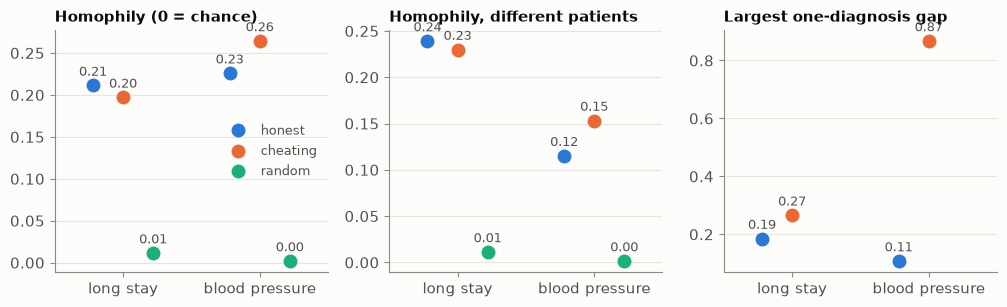

In [2]:
METRICS = {
    "class_insensitive_homophily": "Homophily (0 = chance)",
    "class_insensitive_homophily_excl_same_patient": "Homophily, different patients",
    "max_single_code_outcome_gap": "Largest one-diagnosis gap",
}
fig = nf.cross_task_figure(
    {
        title: {
            TASKS[t]: tuple(
                value(t, c, m) if not (c == "null_model" and m.startswith("max_")) else float("nan")
                for c in ("safe", "leaky", "null_model")
            )
            for t in TASKS
        }
        for m, title in METRICS.items()
    }
)
nf.save(fig, p.figures / "06_both_questions.png")
plt.show()

## Part 2 · Is it just the 2015 code switch?

We rebuild the patient networks on the raw billing codes (which split by era), give every stay an era (ICD-9 only, ICD-10 only, or mixed), and then shuffle the outcomes **within each era**. If era were driving our homophily, the shuffled networks would still show it.

In [3]:
from ehrgraph.eval.aggregate import write_aggregate
from ehrgraph.netstats.homophily import class_insensitive_homophily
from ehrgraph.netstats.task_analysis import (
    PRIMARY_VARIANT,
    SOURCE_CODES_VARIANT,
    coding_era,
    era_stats,
    task_graphs_from_labels,
)

checks, rows = [], []
for task, name in TASKS.items():
    labels = p.labels(task)
    raw = task_graphs_from_labels(p.billing_codes, labels, task, n_null=1)
    concept = task_graphs_from_labels(p.diagnoses, labels, task, n_null=1)
    era = dict(zip(raw.nodes, coding_era(*raw.vectors["safe"]), strict=True))
    for variant, nets in ((SOURCE_CODES_VARIANT, raw), (PRIMARY_VARIANT, concept)):
        s = era_stats(nets.graphs["safe"], era, nets.labels)
        h = {
            c: class_insensitive_homophily(nets.graphs[c], nets.labels)[
                "class_insensitive_homophily"
            ]
            for c in ("safe", "leaky")
        }
        checks.append(
            {
                "question": name,
                "codes": "billing codes" if variant == SOURCE_CODES_VARIANT else "concepts",
                "links across eras": f"{s['icd9_icd10_cross_edge_fraction']:.1%}",
                "homophily (honest)": h["safe"],
                "homophily (cheating)": h["leaky"],
                "homophily from era alone": s["homophily_era_only"],
            }
        )
        for metric, v in {
            "class_insensitive_homophily": h["safe"],
            "icd9_icd10_cross_edge_fraction": s["icd9_icd10_cross_edge_fraction"],
            "homophily_era_only": s["homophily_era_only"],
        }.items():
            rows.append(
                dict(
                    task=task,
                    condition="safe",
                    graph_variant=variant,
                    metric=metric,
                    value=float(v),
                )
            )
        rows.append(
            dict(
                task=task,
                condition="leaky",
                graph_variant=variant,
                metric="class_insensitive_homophily",
                value=float(h["leaky"]),
            )
        )
write_aggregate(rows, p.results / "checks.csv")
pd.DataFrame(checks).set_index(["question", "codes"]).round(3)

links across eras  homophily (honest)  \
question       codes                                                 
long stay      billing codes              0.0%               0.209   
               concepts                   3.0%               0.211   
blood pressure billing codes              0.1%               0.226   
               concepts                   4.1%               0.226   

                              homophily (cheating)  homophily from era alone  
question       codes                                                          
long stay      billing codes                 0.205                     0.004  
               concepts                      0.197                     0.004  
blood pressure billing codes                 0.278                     0.013  
               concepts                      0.264                     0.014

## What we learned

- **Side by side:** both questions have real homophily (0.21 and 0.23 vs about 0 random). Cheating only matters for blood pressure, where the future record contains the diagnosis itself (giveaway 0.87 vs 0.27 for long stay).
- **The 2015 code switch isn't behind our results.** On billing codes almost no links cross eras (0.0–0.1%), but shuffling outcomes within each era leaves homophily of only 0.004 (long stay) and 0.013 (blood pressure). The real numbers are about 50× (long stay) and 17× (blood pressure) bigger.
- **Billing codes vs concepts give the same homophily** for the honest networks (0.21 / 0.23 either way). With billing codes the cheating effect for blood pressure is even a bit bigger (0.28 vs 0.26).

**Overall, for the report:**
1. Similar-patient networks are genuinely organized around outcomes.
2. Peeking at the future only matters when the outcome is written in the record, and how much it matters depends on how the network is built.
3. Simple network tools caught three hidden issues (the code switch, same-patient links, a label quirk) before any machine learning.

Project 2 will test whether the honest networks actually improve predictions.